# T1: EfficientNet knowledge distillation on ImageNet-100
Identical random B0 initialization and minibatch order are used for CE and KD.
The frozen B7 teacher uses the recorded 100-class ImageNet-1K mapping.
$L_{KD}=(1-\lambda)L_{CE}+\lambda T^2 KL(p_T(T)\Vert p_S(T))$,
with $T=3$, $\lambda=0.5$. Hint variants add $0.05L_{hint}$.


In [ ]:
from pathlib import Path
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "code"))


**Latency note:** Timings printed in the training cells are provisional. The final report and analysis below use the controlled comparison in `reprofile.ipynb`, which reloads the saved checkpoints and times them together after training.

In [1]:
from common import *
from torchvision.models import efficientnet_b0, efficientnet_b7, EfficientNet_B7_Weights

seed_all(42)
mapping = json.loads((ROOT / "results" / "imagenet_class_mapping.json").read_text())
class_indices = torch.tensor([r["imagenet1k_index"] for r in mapping], device=DEVICE)


def data(split):
    raw = torch.load(ROOT / "data" / f"imagenet100_{split}.pt", weights_only=True)
    images = raw["images"].float() / 255
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    return TensorDataset((images - mean) / std, raw["labels"])


train, val = data("train"), data("validation")
print("Training/validation:", len(train), len(val), "Device:", DEVICE)
teacher = efficientnet_b7(weights=EfficientNet_B7_Weights.DEFAULT).to(DEVICE).eval()
teacher.requires_grad_(False)


Training/validation: 500 200 Device: xpu


## Cache deterministic frozen teacher outputs and verify feature shapes
The input transform is fixed resize plus normalization. Caching therefore
reuses the same teacher targets while avoiding repeated B7 inference. Logits
remain FP32; hint maps use FP16 storage with small quantization error.


In [2]:
features = {}
hooks = [
    teacher.features[1].register_forward_hook(
        lambda m, a, o: features.update(direct=o)
    ),
    teacher.features[5].register_forward_hook(
        lambda m, a, o: features.update(adapted=o)
    ),
]


@torch.no_grad()
def cache_teacher(ds, split):
    path = ROOT / "data" / f"teacher_{split}.pt"
    if path.exists():
        return torch.load(path, weights_only=True)
    zs, ds_features, as_features = [], [], []
    sync()
    start = time.perf_counter()
    for x, y in loader(ds, batch=8):
        z = teacher(x.to(DEVICE))[:, class_indices]
        zs.append(z.cpu())
        if split == "train":
            ds_features.append(features["direct"].cpu().half())
            as_features.append(features["adapted"].cpu().half())
    sync()
    result = {"logits": torch.cat(zs), "seconds": time.perf_counter() - start}
    if split == "train":
        result.update(direct=torch.cat(ds_features), adapted=torch.cat(as_features))
    torch.save(result, path)
    return result


targets = cache_teacher(train, "train")
val_targets = cache_teacher(val, "validation")
for h in hooks:
    h.remove()
teacher_profile = profile(teacher, (1, 3, 224, 224))


def accuracy(logits, labels):
    top = logits.topk(5, dim=1).indices
    return {
        "top1": 100 * (top[:, 0] == labels).float().mean().item(),
        "top5": 100 * (top == labels[:, None]).any(1).float().mean().item(),
    }


teacher_result = {**accuracy(val_targets["logits"], val.tensors[1]), **teacher_profile}
del teacher
torch.xpu.empty_cache()


def student():
    net = efficientnet_b0(weights=None)
    net.classifier[1] = nn.Linear(net.classifier[1].in_features, 100)
    return net.to(DEVICE)


initial = student()
initial_state = copy.deepcopy(initial.state_dict())
del initial
print("Teacher:", teacher_result)
print("Cached feature shapes:", targets["direct"].shape, targets["adapted"].shape)


Teacher: {'top1': 85.00000238418579, 'top5': 96.49999737739563, 'parameters': 66347960, 'macs': 5169865152, 'size_mib': 254.28392791748047, 'latency_ms': 122.71590000000288, 'timings_ms': [117.88460000025225, 112.67540000017107, 105.4137000000992, 114.57180000024891, 158.91310000006342, 224.17630000018107, 101.639299999988, 101.46100000019942, 101.4525999999023, 103.8130000001729, 424.6422999999595, 451.20559999986654, 487.03919999979917, 499.478100000033, 485.16909999989366, 496.43909999986136, 310.12280000004466, 127.5471999997535, 111.192100000153, 110.61479999989388]}
Cached feature shapes: torch.Size([500, 32, 112, 112]) torch.Size([500, 224, 14, 14])


## Loss, validation and training helpers
Hint tensors are cached in FP16 for storage and converted to FP32 for MSE.
Only the student and (when present) the adapter receive gradients.


In [3]:
def kd_loss(z, t, y):
    ce = F.cross_entropy(z, y)
    kl = F.kl_div(
        F.log_softmax(z / 3, dim=1), F.softmax(t / 3, dim=1), reduction="batchmean"
    )
    return 0.5 * ce + 0.5 * 9 * kl


@torch.no_grad()
def assess(net):
    net.eval()
    zs = []
    total = 0
    for x, y in loader(val, batch=16):
        z = net(x.to(DEVICE))
        zs.append(z.cpu())
        total += F.cross_entropy(z, y.to(DEVICE), reduction="sum").item()
    acc = accuracy(torch.cat(zs), val.tensors[1])
    acc["loss"] = total / len(val)
    acc["accuracy"] = acc["top1"]
    return acc


def train_variant(name, state, epochs, hint=None):
    seed_all(42)
    net = student()
    net.load_state_dict(state)
    adapter = nn.Conv2d(80, 224, 1).to(DEVICE) if hint == "adapted" else None
    captured = {}
    handle = None
    if hint:
        layer = net.features[0] if hint == "direct" else net.features[4]
        handle = layer.register_forward_hook(lambda m, a, o: captured.update(h=o))
    parameters = list(net.parameters()) + (
        list(adapter.parameters()) if adapter else []
    )
    optimizer = torch.optim.Adam(parameters, lr=0.001)
    # Adapter construction must not shift the student's dropout RNG sequence.
    seed_all(42)
    ids = TensorDataset(torch.arange(len(train)))
    batches = loader(ids, True, 42, batch=16)
    history = []
    verification = {}
    sync()
    start = time.perf_counter()
    for epoch in range(epochs):
        net.train()
        total = ce_total = hint_total = correct = n = 0
        for step, (idx,) in enumerate(batches):
            x = train.tensors[0][idx].to(DEVICE)
            y = train.tensors[1][idx].to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            z = net(x)
            ce = F.cross_entropy(z, y)
            loss = (
                ce
                if name == "independent"
                else kd_loss(z, targets["logits"][idx].to(DEVICE), y)
            )
            hl = torch.tensor(0.0, device=DEVICE)
            if hint:
                hs = captured["h"]
                ht = targets[hint][idx].to(DEVICE).float()
                projected = adapter(hs) if adapter else hs
                assert projected.shape == ht.shape
                hl = F.mse_loss(projected, ht)
                loss = loss + 0.05 * hl
                if epoch == step == 0:
                    verification.update(
                        student_shape=list(hs.shape),
                        teacher_shape=list(ht.shape),
                        after_adapter_shape=list(projected.shape),
                    )
            loss.backward()
            if epoch == step == 0 and hint:
                verification.update(
                    student_gradient_nonzero=any(
                        p.grad is not None and bool(p.grad.abs().sum() > 0)
                        for p in net.parameters()
                    ),
                    teacher_frozen=True,
                    teacher_targets_require_grad=targets[hint].requires_grad,
                    adapter_gradient_nonzero=(
                        any(
                            p.grad is not None and bool(p.grad.abs().sum() > 0)
                            for p in adapter.parameters()
                        )
                        if adapter
                        else None
                    ),
                )
            optimizer.step()
            total += loss.item() * len(y)
            ce_total += ce.item() * len(y)
            hint_total += hl.item() * len(y)
            correct += (z.argmax(1) == y).sum().item()
            n += len(y)
        history.append(
            {
                "epoch": epoch + 1,
                "train": {
                    "loss": total / n,
                    "ce": ce_total / n,
                    "hint": hint_total / n,
                    "accuracy": 100 * correct / n,
                },
                "validation": assess(net),
            }
        )
        print(name, history[-1], flush=True)
    sync()
    elapsed = time.perf_counter() - start
    if handle:
        handle.remove()
    torch.save(net.state_dict(), ROOT / "checkpoints" / f"t1_{name}.pt")
    if adapter:
        torch.save(adapter.state_dict(), ROOT / "checkpoints" / "t1_adapter.pt")
    record = {
        "history": history,
        "seconds": elapsed,
        "updates": epochs * len(batches),
        "metrics": {**assess(net), **profile(net, (1, 3, 224, 224))},
        "verification": verification,
        "adapter_parameters": (
            sum(p.numel() for p in adapter.parameters()) if adapter else 0
        ),
    }
    state = {k: v.cpu().clone() for k, v in net.state_dict().items()}
    del net, adapter
    torch.xpu.empty_cache()
    return state, record


## Independent and logit-KD students: three epochs each


In [4]:
_, ce_run = train_variant("independent", initial_state, 3)
kd_state, kd_run = train_variant("logit_kd", initial_state, 3)


independent {'epoch': 1, 'train': {'loss': 4.9167129440307615, 'ce': 4.9167129440307615, 'hint': 0.0, 'accuracy': 0.4}, 'validation': {'top1': 0.9999999776482582, 'top5': 5.000000074505806, 'loss': 4.646208572387695, 'accuracy': 0.9999999776482582}}
independent {'epoch': 2, 'train': {'loss': 4.680897644042969, 'ce': 4.680897644042969, 'hint': 0.0, 'accuracy': 1.2}, 'validation': {'top1': 0.4999999888241291, 'top5': 3.500000014901161, 'loss': 4.66860689163208, 'accuracy': 0.4999999888241291}}
independent {'epoch': 3, 'train': {'loss': 4.635717758178711, 'ce': 4.635717758178711, 'hint': 0.0, 'accuracy': 0.6}, 'validation': {'top1': 1.4999999664723873, 'top5': 7.500000298023224, 'loss': 12.60608949661255, 'accuracy': 1.4999999664723873}}
logit_kd {'epoch': 1, 'train': {'loss': 4.0200520362854, 'ce': 4.820937171936035, 'hint': 0.0, 'accuracy': 0.2}, 'validation': {'top1': 0.9999999776482582, 'top5': 5.000000074505806, 'loss': 4.632829856872559, 'accuracy': 0.9999999776482582}}
logit_kd {'e

## Two separate hint experiments: two additional epochs each
Direct: $h_S,h_T\in\mathbb R^{B\times32\times112\times112}$.
Adapted: $r_\theta:\mathbb R^{80}\rightarrow\mathbb R^{224}$ is a 1x1 convolution.
Both branches restart from the same logit-KD checkpoint; the adapter is discarded for deployment.


In [5]:
_, direct_run = train_variant("direct_hint", kd_state, 2, "direct")
_, adapted_run = train_variant("adapted_hint", kd_state, 2, "adapted")
runs = {
    "independent": ce_run,
    "logit_kd": kd_run,
    "direct_hint": direct_run,
    "adapted_hint": adapted_run,
}
save_json(
    "task1",
    {
        "teacher": teacher_result,
        "teacher_cache_seconds": targets["seconds"] + val_targets["seconds"],
        "train_examples": len(train),
        "validation_examples": len(val),
        "train_classes": len(train.tensors[1].unique()),
        "validation_classes": len(val.tensors[1].unique()),
        "runs": runs,
    },
)
curves(runs, "t1_training")
fig, ax = plt.subplots(figsize=(6, 3))
for name in ["direct_hint", "adapted_hint"]:
    ax.plot(
        [1, 2],
        [h["train"]["hint"] for h in runs[name]["history"]],
        marker="o",
        label=name,
    )
ax.set(xlabel="Additional epoch", ylabel="Mean squared hint loss")
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "figures" / "t1_hint.png", dpi=150)
plt.close(fig)
for name, run in runs.items():
    print(name, run["metrics"])


direct_hint {'epoch': 1, 'train': {'loss': 5.546518447875976, 'ce': 4.562158958435059, 'hint': 34.36986022949219, 'accuracy': 1.2}, 'validation': {'top1': 2.9999999329447746, 'top5': 7.000000029802322, 'loss': 5.291741123199463, 'accuracy': 2.9999999329447746}}
direct_hint {'epoch': 2, 'train': {'loss': 5.479126304626464, 'ce': 4.506600028991699, 'hint': 33.826464263916016, 'accuracy': 2.4}, 'validation': {'top1': 1.4999999664723873, 'top5': 7.000000029802322, 'loss': 4.6883672332763675, 'accuracy': 1.4999999664723873}}
adapted_hint {'epoch': 1, 'train': {'loss': 5.92138304901123, 'ce': 4.547376091003418, 'hint': 42.07450003051758, 'accuracy': 1.6}, 'validation': {'top1': 0.9999999776482582, 'top5': 5.000000074505806, 'loss': 5.893870582580567, 'accuracy': 0.9999999776482582}}
adapted_hint {'epoch': 2, 'train': {'loss': 5.7872468376159665, 'ce': 4.4893206710815425, 'hint': 40.21775115966797, 'accuracy': 2.4}, 'validation': {'top1': 2.500000037252903, 'top5': 7.999999821186066, 'loss': 

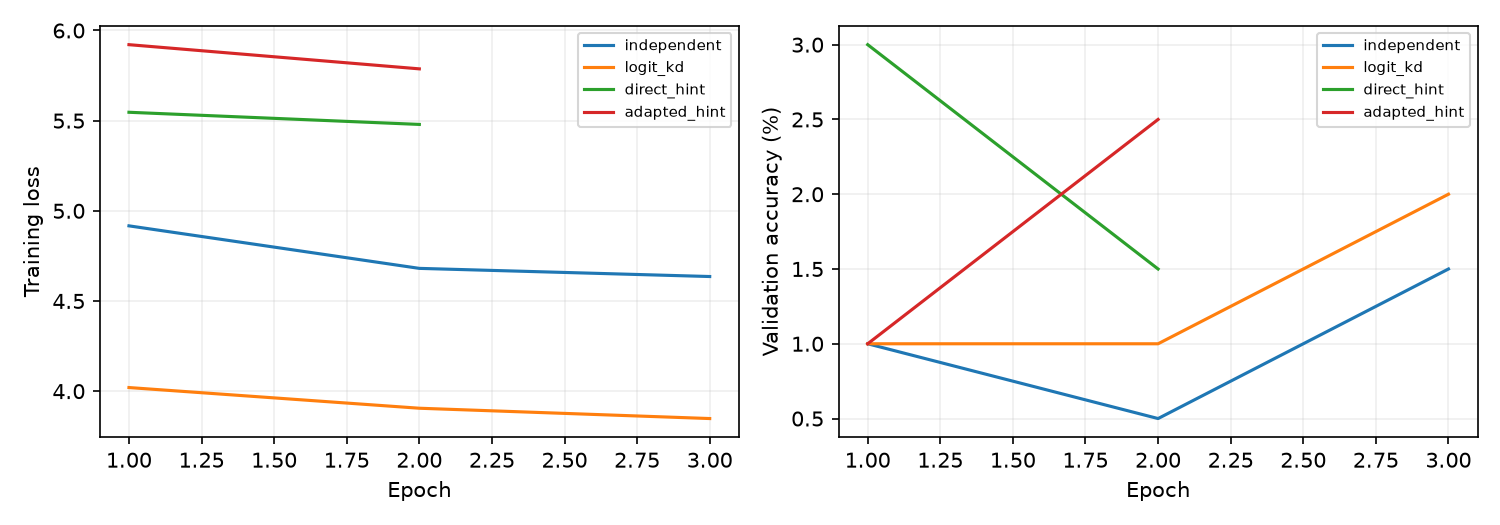

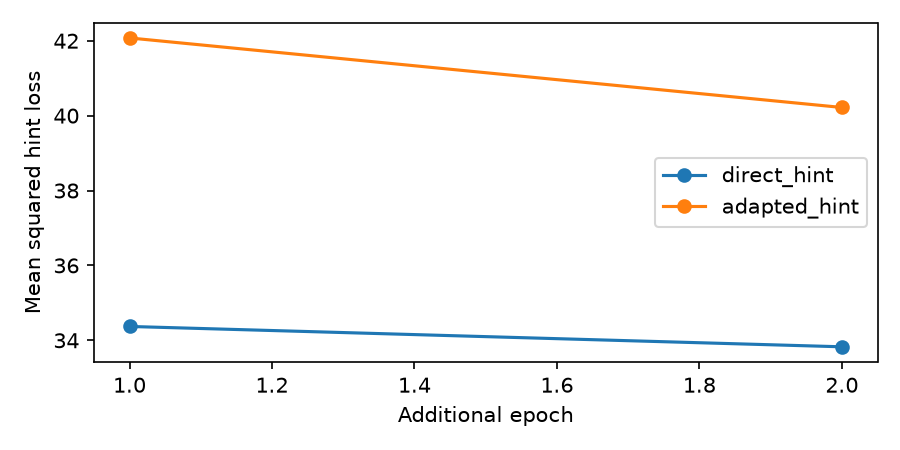

In [ ]:
from IPython.display import Image, display

display(Image(filename=str(project_root / "figures" / "t1_training.png")))
display(Image(filename=str(project_root / "figures" / "t1_hint.png")))


# Analysis

## T1.1: Independent Training and Logit KD

**Q1.** Did KD improve accuracy or convergence? Compare the training curves and final results. Did KD change the student's inference cost?

**Answer:**

| Model | Top-1 (%) | Top-5 (%) | Parameters | Median latency (ms) |
| --- | --- | --- | --- | --- |
| EfficientNet-B7 teacher | 85.00 | 96.50 | 66347960 | 61.11 |
| Independent | 1.50 | 7.50 | 4135648 | 9.87 |
| Logit KD | 2.00 | 7.50 | 4135648 | 9.95 |

Both B0 models began with identical weights and used seed 42, Adam (learning rate 0.001), batch size 16, three epochs and 96 updates each. The fixed subset contains 500 training and 200 validation images, covering 100 and 100 classes respectively; no test set was used for model selection. Systematic blocks span the class-ordered source, with the two short-class gaps filled from their midpoint rows to give exactly five training images per class. Image indices are stored with the subset tensors; the 100-label mapping is in `results/imagenet_class_mapping.json`. The source is `clane9/imagenet-100`, whose images are already reduced to a 160-pixel short side; we resize to 224 x 224 and apply ImageNet normalization. No random augmentation is used. Teacher logits are cached in FP32; hint maps use FP16 storage and are converted to FP32 for MSE, introducing small storage quantization error.

$$L_{KD}=(1-\lambda)L_{CE}+\lambda T^2\,D_{KL}(p_T(T)\Vert p_S(T)),\quad T=3,\quad\lambda=0.5.$$

KD changed final Top-1 accuracy by +0.50 percentage points and Top-5 by +0.00 points. Independent training CE fell from 4.917 to 4.636; KD training CE fell from 4.821 to 4.590. However, final validation CE was 12.606 and 10.069, respectively, and both Top-1 scores remained near the 1% chance level. Thus the students are substantially undertrained and the curves do not demonstrate stable validation convergence. The plotted objectives also differ: KD includes KL while the independent objective is CE; the JSON histories separately record CE. Both deployed students have exactly the same architecture and parameter count. Measured latency differences reflect runtime variability, not an extra KD operation at inference.

![T1 training objectives and validation Top-1 accuracy. Hint epochs are additional epochs after the common KD checkpoint.](../figures/t1_training.png)

T1 training objectives and validation Top-1 accuracy. Hint epochs are additional epochs after the common KD checkpoint.


## T1.2: Feature Matching Without an Adapter

**Q1.** Report the teacher and student feature dimensions, hint-loss curve, and validation accuracy. Why can these features be compared directly? Does having the same shape mean they contain the same information?

**Answer:**

Teacher `features[1]` and student `features[0]` both produced [16, 32, 112, 112] on the first batch. No adapter was used. Two additional epochs (64 updates) from the logit-KD checkpoint gave Top-1 1.50% and Top-5 7.00%. Mean hint losses by epoch were 34.369860, 33.826464.

$$L=L_{KD}+0.05L_{hint},\qquad L_{hint}=\mathrm{MSE}(h_S,h_T).$$

Matching batch, channel and spatial dimensions permits elementwise MSE. Equal shapes do not imply equal information: independently learned channels need not represent the same patterns, scales or semantics. The teacher layer also includes an MBConv stage while the student layer is the stem.

![Direct and adapted feature MSE during the two additional epochs.](../figures/t1_hint.png)

Direct and adapted feature MSE during the two additional epochs.


## T1.3: Feature Matching With an Adapter

**Q1.** Show the feature shapes before and after the adapter, its parameter count, hint loss, and validation accuracy. Why is the adapter needed in this case?

**Answer:**

The student feature shape was [16, 80, 14, 14]; the teacher shape was [16, 224, 14, 14]. A trainable 1 x 1 convolution changed the student shape to [16, 224, 14, 14]. Its parameter count is 80 x 224 + 224 = 18,144, including bias. Checks confirmed nonzero gradients in both the student and adapter, with detached targets from a frozen teacher.

$$L_{hint}=\mathrm{MSE}(r_\theta(h_S),h_T).$$

The adapter is required because 80 student channels cannot be compared elementwise with 224 teacher channels. It learns a channel projection at each spatial location; both maps already have 14 x 14 spatial resolution. This run started from a separate copy of the same KD checkpoint. After 64 updates, Top-1 was 2.50% and Top-5 8.00%. Hint losses were 42.074500, 40.217751. The adapter is removed for deployment.


## T1.4: Final Comparison

**Q1.** Compare independent training, logit KD, direct feature matching, and adapted feature matching. Which configuration performed best? What additional training cost did feature matching introduce?

**Answer:**

| Configuration | Top-1 (%) | Top-5 (%) | Cumulative training loop (s) | Deployed parameters | Latency (ms) |
| --- | --- | --- | --- | --- | --- |
| Independent | 1.50 | 7.50 | 118.92 | 4135648 | 9.87 |
| Logit KD | 2.00 | 7.50 | 70.30 | 4135648 | 9.95 |
| Direct hint | 1.50 | 7.00 | 114.48 | 4135648 | 9.52 |
| Adapted hint | 2.50 | 8.00 | 114.21 | 4135648 | 10.36 |
The highest final Top-1 result was Adapted hint (2.50%). Direct and adapted hints added 44.18 s and 43.92 s, respectively, beyond KD training. Hint variants have two more epochs, so this is not an equal-total-budget comparison. Teacher target generation took 60.25 s (shared preprocessing cost, excluded from the table). Caching is possible because inputs and teacher weights are fixed. Feature training adds feature storage, transfer and MSE computation; the adapted case also adds projection parameters and gradients. None of these additions changes the deployed B0 inference graph.
